# Table detection: final model (1024 px, 60 epochs)

The scaling study showed the 18,000-page model **had not finished learning** after
20 epochs at 640 px. This notebook trains the final model on the **same pages**
with these changes:

| | Scaling study (18k run) | This notebook |
|---|---|---|
| Epochs | 20 | **60** |
| Image size | 640 px | **1024 px** (about the pages' real size) |
| Early-stopping patience | 5 | **10** |
| Optimizer | AdamW, lr 0.002 (picked by Ultralytics) | **SGD, lr 0.01** |
| Train / validation / test pages | 18,000 / 500 / 500 | same pages |
| Model, batch, seed, augmentation | yolo11n, 8, 42, no mosaic/flips | unchanged |

**Why set the optimizer?** With `optimizer="auto"`, Ultralytics picks AdamW for
short runs and SGD for long ones. A 30-epoch 896 px run (AdamW) was no better
than the 640 px model, while this 60-epoch setup (SGD) was clearly better. We
write the optimizer down explicitly, so the setting is visible, not hidden.

**How to run:** Kaggle notebook with **GPU** and **Internet** on, then
*Save Version → Save & Run All*. Expect about 1 hour of download and about
8 hours of training. Everything in `/kaggle/working` is saved with the version.

## 1. Install

In [1]:
%pip install -q "ultralytics==8.3.221" "pyarrow==21.0.0" "huggingface_hub==0.36.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
bigframes 2.48.0 requires pyarrow>=23.0.1, but you have pyarrow 21.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [2]:
import json
import shutil
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import torch
import yaml
from huggingface_hub import HfFileSystem
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO, settings

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 3. Settings

In [3]:
# --- What this run changes ------------------------------------------------
EPOCHS = 60
PATIENCE = 10
IMGSZ = 1024
OPTIMIZER = "SGD"
LR0 = 0.01      # Starting learning rate.
MOMENTUM = 0.9

# --- Same as the scaling study ---------------------------------------------
PRETRAINED = "yolo11n.pt"
BATCH = 8
SEED = 42
PAGES_TRAIN = 18000
PAGES_VALIDATION = 500
PAGES_TEST = 500
MAX_PAGES_PER_DOCUMENT = 10

# --- Data source -------------------------------------------------------------
REPO = "docling-project/DocLayNet-v1.2"
REVISION = "85cadd47c3ac59e1a2c3677ec72a02b143d96430"  # Pinned so the data never changes.
TABLE_CATEGORY_ID = 9  # "Table" in DocLayNet.
TABLE_CLASS_ID = 0     # "table" in our one-class dataset.

# --- Folders -----------------------------------------------------------------
DATA = Path("/kaggle/temp/table_data")   # Downloaded pages. Not saved.
OUTPUT = Path("/kaggle/working/final_1024")  # Model and results. Saved with the version.
WORKERS = 2                              # Kaggle machines have few CPU cores.

DATA.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
fs = HfFileSystem()
ROOT = f"datasets/{REPO}@{REVISION}"

settings.update({"wandb": False, "mlflow": False, "comet": False, "clearml": False})
assert torch.cuda.is_available(), "Turn on a GPU in the notebook settings."
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 4. List every page in the dataset

Reads only the page metadata and annotation classes, not the images. For every
page we learn: which file it is in, which document it came from, its document
type, and how many tables it has.

In [4]:
def build_index(split):
    pages = []
    files = sorted(fs.glob(f"{ROOT}/data/{split}-*.parquet"))

    for file in tqdm(files, desc=f"Index {split}"):
        with fs.open(file, "rb", block_size=64 * 1024) as stream:  # Small reads: two thin columns.
            parquet = pq.ParquetFile(stream, pre_buffer=False)

            for group in range(parquet.num_row_groups):
                rows = parquet.read_row_group(
                    group, columns=["metadata", "category_id"], use_threads=False
                ).to_pylist()

                for row_number, row in enumerate(rows):
                    meta = row["metadata"]
                    pages.append({
                        "file": file,
                        "group": group,
                        "row": row_number,
                        "page_hash": meta["page_hash"],
                        "domain": meta["doc_category"],
                        "document": f"{meta['collection']}/{meta['original_filename']}",
                        "tables": row["category_id"].count(TABLE_CATEGORY_ID),
                    })
    return pd.DataFrame(pages)

## 5. Choose the pages

Same selection as the scaling study, so we get the same pages:

1. **Shuffle, then keep at most 10 pages per document**, so one long report
   cannot dominate.
2. **Stratify** by document type and "has a table / has no table", so every kind
   of page is represented in proportion to its size.

In [5]:
def allocate_quotas(group_sizes, total):
    # One place per group, the rest shared in proportion to group size.
    quotas = pd.Series(1, index=group_sizes.index)
    spare = group_sizes - 1
    exact_share = (total - len(group_sizes)) * spare / max(spare.sum(), 1)
    quotas = quotas + exact_share.astype(int)

    # Rounding down leaves a few places: give them to the largest remainders.
    leftover = total - quotas.sum()
    if leftover > 0:
        remainders = (exact_share - exact_share.astype(int))[quotas < group_sizes]
        quotas[remainders.nlargest(leftover).index] += 1
    return quotas


def select_pages(index, count):
    pool = index.sample(frac=1, random_state=SEED)
    pool = pool.groupby("document", sort=False).head(MAX_PAGES_PER_DOCUMENT)
    pool = pool.assign(has_table=pool["tables"] > 0)

    groups = pool.groupby(["domain", "has_table"], sort=True)
    quotas = allocate_quotas(groups.size(), count)
    selected = pd.concat([pages.head(quotas[name]) for name, pages in groups])

    assert len(selected) == count
    return selected

In [6]:
pages = {
    "train": select_pages(build_index("train"), PAGES_TRAIN).sample(frac=1, random_state=SEED),
    "validation": select_pages(build_index("validation"), PAGES_VALIDATION),
    "test": select_pages(build_index("test"), PAGES_TEST),
}

for split, selected in pages.items():
    print(f"{split:<11} {len(selected):>6,} pages, {(selected['tables'] > 0).mean():.0%} with a table")

Index train:   0%|          | 0/72 [00:00<?, ?it/s]

Index validation:   0%|          | 0/7 [00:00<?, ?it/s]

Index test:   0%|          | 0/6 [00:00<?, ?it/s]

train       18,000 pages, 21% with a table
validation     500 pages, 24% with a table
test           500 pages, 23% with a table


### Checks before downloading

1. **No document appears in two splits.** Otherwise the model could score well
   by memorising a document's layout.
2. **Same pages as the scaling study** (optional). Add `selected_pages.json` from
   the scaling study as a Kaggle dataset to run this check.

In [7]:
documents = {split: set(selected["document"]) for split, selected in pages.items()}
assert documents["train"].isdisjoint(documents["validation"])
assert documents["train"].isdisjoint(documents["test"])
assert documents["validation"].isdisjoint(documents["test"])
print("No document is shared between splits.")

previous = list(Path("/kaggle/input").rglob("selected_pages.json"))
if previous:
    old = json.loads(previous[0].read_text())
    for split, selected in pages.items():
        assert {r["page_hash"] for r in old[split]} == set(selected["page_hash"]), split
    print("Same pages as the scaling study.")
else:
    print("selected_pages.json not attached, skipping that check.")

No document is shared between splits.
selected_pages.json not attached, skipping that check.


## 6. Download the pages and write YOLO labels

DocLayNet boxes are pixels `[left, top, width, height]`. YOLO wants
`class center_x center_y width height`, each divided by the page size. Pages
without a table get an empty label file, so the model also learns what a
table-free page looks like.

In [8]:
def to_yolo_labels(row, width, height):
    lines = []
    for category, (left, top, box_width, box_height) in zip(row["category_id"], row["bboxes"]):
        if category != TABLE_CATEGORY_ID:
            continue
        # Clip to the page in case an annotation runs over the edge.
        right = min(left + box_width, width)
        bottom = min(top + box_height, height)
        left, top = max(left, 0), max(top, 0)
        lines.append(f"{TABLE_CLASS_ID} "
                     f"{(left + right) / 2 / width:.6f} {(top + bottom) / 2 / height:.6f} "
                     f"{(right - left) / width:.6f} {(bottom - top) / height:.6f}")
    return lines


def download_split(selected, split):
    images_dir = DATA / "images" / split
    labels_dir = DATA / "labels" / split
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    image_paths = {}
    progress = tqdm(total=len(selected), desc=f"Download {split}")

    for file, file_pages in selected.groupby("file"):
        with fs.open(file, "rb", block_size=8 * 1024 * 1024) as stream:  # Big reads: whole images.
            parquet = pq.ParquetFile(stream, pre_buffer=False)

            for group, group_pages in file_pages.groupby("group"):
                block = parquet.read_row_group(
                    int(group), columns=["image", "bboxes", "category_id", "metadata"],
                    use_threads=False,
                )
                for row in block.take(group_pages["row"].tolist()).to_pylist():
                    raw = row["image"]["bytes"]
                    with Image.open(BytesIO(raw)) as image:
                        width, height = image.size
                        suffix = image.format.lower()

                    page_hash = row["metadata"]["page_hash"]
                    image_path = images_dir / f"{page_hash}.{suffix}"
                    image_path.write_bytes(raw)  # Saved as-is: no re-encoding.
                    labels = to_yolo_labels(row, width, height)
                    (labels_dir / f"{page_hash}.txt").write_text("\n".join(labels))

                    image_paths[page_hash] = str(image_path)
                    progress.update()
    progress.close()

    # Keep the order of `selected`, not the order the files were read in.
    return [image_paths[page_hash] for page_hash in selected["page_hash"]]

In [9]:
image_lists = {split: download_split(selected, split) for split, selected in pages.items()}

Download train:   0%|          | 0/18000 [00:00<?, ?it/s]

Download validation:   0%|          | 0/500 [00:00<?, ?it/s]

Download test:   0%|          | 0/500 [00:00<?, ?it/s]

## 7. Write the dataset config

In [10]:
for split, paths in image_lists.items():
    (DATA / f"{split}.txt").write_text("\n".join(paths))

data_config = DATA / "data.yaml"
data_config.write_text(yaml.safe_dump({
    "path": str(DATA),
    "train": "train.txt",
    "val": "validation.txt",
    "test": "test.txt",
    "names": {TABLE_CLASS_ID: "table"},
}))
print(data_config.read_text())

names:
  0: table
path: /kaggle/temp/table_data
test: test.txt
train: train.txt
val: validation.txt



## 8. Train

- `epochs=60, patience=10`: up to 60 epochs; stop early if validation mAP has
  not improved for 10 epochs in a row.
- `imgsz=1024`: pages go into the network at 1024 px.
- `optimizer="SGD", lr0=0.01, momentum=0.9`: what Ultralytics picked for the
  earlier 1024 px run, written out explicitly.
- `mosaic=0, fliplr=0, flipud=0`: these augmentations stitch pages together or
  mirror them. Real documents never look like that.

Ultralytics prints a progress bar for every epoch and keeps the best epoch's
weights as `best.pt`.

In [11]:
model = YOLO(PRETRAINED)
model.train(
    data=str(data_config),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    device=0,
    workers=WORKERS,
    mosaic=0.0,
    fliplr=0.0,
    flipud=0.0,
    optimizer=OPTIMIZER,
    lr0=LR0,
    momentum=MOMENTUM,
    project=str(OUTPUT),
    name="train",
    exist_ok=True,
)

run_dir = Path(model.trainer.save_dir)
best_weights = OUTPUT / "best_1024_60ep.pt"
shutil.copy2(run_dir / "weights" / "best.pt", best_weights)
print("Best weights saved to", best_weights)

New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.221 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/temp/table_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.9, mosaic=0.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None

## 9. Did it converge?

If the curve has flattened before the last epoch, more epochs would not help.

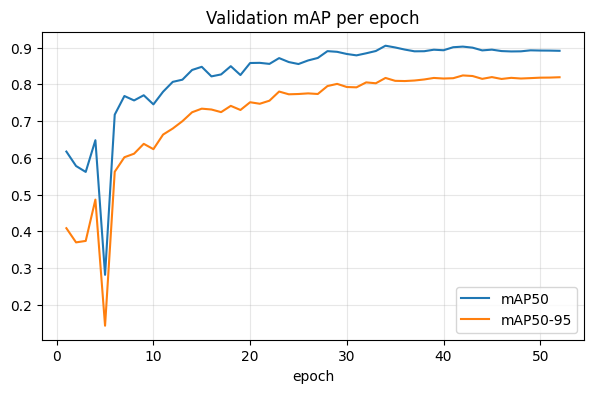

In [12]:
history = pd.read_csv(run_dir / "results.csv")
history.columns = history.columns.str.strip()

plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["metrics/mAP50(B)"], label="mAP50")
plt.plot(history["epoch"], history["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("epoch")
plt.title("Validation mAP per epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig(OUTPUT / "training_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Score on validation and compare

Same 500 validation pages and same scoring settings as the earlier runs.

In [13]:
def evaluate(weights, split):
    metrics = YOLO(str(weights)).val(
        data=str(data_config),
        split=split,
        imgsz=IMGSZ,
        batch=4,
        device=0,
        half=False,
        rect=False,
        conf=0.001,  # Keep low-confidence boxes so the PR curve is complete.
        project=str(OUTPUT),
        name=split,
        exist_ok=True,
    )
    return {
        "mAP50": round(float(metrics.box.map50), 4),
        "mAP50_95": round(float(metrics.box.map), 4),
        "precision": round(float(metrics.box.mp), 4),
        "recall": round(float(metrics.box.mr), 4),
    }


validation_scores = evaluate(best_weights, "val")
(OUTPUT / "validation_results.json").write_text(json.dumps(validation_scores, indent=2))

# Earlier validation results on the same pages. If your Kaggle rerun of the
# scaling study gave slightly different 18k numbers, put those in the first row.
comparison = pd.DataFrame({
    "640 px, 20 epochs (scaling study)": {"mAP50": 0.8411, "mAP50_95": 0.7478, "precision": 0.9178, "recall": 0.7444},
    "896 px, 30 epochs, AdamW (Kaggle)": {"mAP50": 0.8516, "mAP50_95": 0.7561, "precision": 0.8574, "recall": 0.8015},
    "1024 px, 60 epochs, SGD (rented GPU)": {"mAP50": 0.8836, "mAP50_95": 0.8092, "precision": 0.9335, "recall": 0.8056},
    "1024 px, 60 epochs, SGD (this run)": validation_scores,
}).T
comparison

Ultralytics 8.3.221 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3455.0±1192.9 MB/s, size: 337.7 KB)
val: Scanning /kaggle/temp/table_data/labels/validation.cache... 500 images, 382 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 573.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 17.3it/s 7.2s0.1s
                   all        500        180       0.92      0.835      0.894      0.809
Speed: 2.6ms preprocess, 8.5ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /kaggle/working/final_1024/val


,mAP50,mAP50_95,precision,recall
"640 px, 20 epochs (scaling study)",0.8411,0.7478,0.9178,0.7444
"896 px, 30 epochs, AdamW (Kaggle)",0.8516,0.7561,0.8574,0.8015
"1024 px, 60 epochs, SGD (rented GPU)",0.8836,0.8092,0.9335,0.8056
"1024 px, 60 epochs, SGD (this run)",0.8943,0.8090,0.9204,0.8350


## 11. Final test score (run once, at the very end)

Validation was used to make decisions, so it is slightly optimistic. Turn this
on once you have decided this is the model you will report.

For the report: the test split was used before, to score the earlier models.

In [14]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    test_scores = evaluate(best_weights, "test")
    (OUTPUT / "test_results.json").write_text(json.dumps(test_scores, indent=2))
    print(json.dumps(test_scores, indent=2))
else:
    print("Skipped. Set RUN_FINAL_TEST = True when the model is final.")

Skipped. Set RUN_FINAL_TEST = True when the model is final.
